<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">

# Visión por Computadora 3D — Tarea 1


## 1.- Importamos lo necesario

Se utiliza un entorno local con PyTorch y CUDA. La primera ejecución requiere conexión a Internet para descargar Fruits-360 y Depth Anything V2. En las siguientes se pueden reutilizar los datos procesados y los modelos guardados, sin repetir los pasos más costosos.


In [2]:
import os
import glob
import subprocess
import time
import random
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from PIL import Image
from scipy.ndimage import binary_fill_holes
from transformers import AutoModelForDepthEstimation

print('Python y archivos en:', Path.cwd())
print('PyTorch:', torch.__version__)
print('Compilación CUDA:', torch.version.cuda)


Python y archivos en: c:\Users\tolot\Documents\UBA\2026\5B\VPC3D
PyTorch: 2.6.0+cu124
Compilación CUDA: 12.4



**Configuración de GPU**

Se utiliza CUDA si hay una GPU disponible y se fija una semilla para facilitar la reproducibilidad. Los tamaños de lote para la estimación de profundidad y el entrenamiento se ajustan según la memoria de la GPU.


In [3]:
# Configuración para GPU local con CUDA.
REQUIERE_GPU = True
DISP = 'cuda' if torch.cuda.is_available() else 'cpu'
if REQUIERE_GPU and DISP == 'cpu':
    raise RuntimeError(
        'PyTorch no detecta una GPU CUDA. Revisá el driver NVIDIA y que hayas '
        'instalado la variante CUDA de PyTorch para este entorno virtual. '
        f'Versión de PyTorch: {torch.__version__}, CUDA: {torch.version.cuda}. '
        'Si querés ejecutar en CPU, cambiá REQUIERE_GPU=False.'
    )

SEMILLA = 0
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
if DISP == 'cuda':
    torch.cuda.manual_seed_all(SEMILLA)
    propiedades_gpu = torch.cuda.get_device_properties(0)
    memoria_gpu_gb = propiedades_gpu.total_memory / 1024**3
    print('GPU:', propiedades_gpu.name)
    print(f'VRAM total: {memoria_gpu_gb:.1f} GB')
    # Lotes conservadores: se pueden aumentar si queda suficiente VRAM.
    LOTE_PROFUNDIDAD = 1 if memoria_gpu_gb < 6 else (2 if memoria_gpu_gb < 10 else 4)
    LOTE_ENTRENAMIENTO = 8 if memoria_gpu_gb < 6 else (16 if memoria_gpu_gb < 10 else 32)
else:
    LOTE_PROFUNDIDAD = 1
    LOTE_ENTRENAMIENTO = 8
print('Dispositivo:', DISP)
print('Lote profundidad:', LOTE_PROFUNDIDAD, '| lote entrenamiento:', LOTE_ENTRENAMIENTO)


GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
VRAM total: 6.0 GB
Dispositivo: cuda
Lote profundidad: 1 | lote entrenamiento: 8


### Guardado de datos y modelos

Para no tener que repetir los cálculos más largos, se guardan los datos procesados en `artefactos_frutas3d/datos_procesados/`, los modelos en `artefactos_frutas3d/modelos/` y los resultados en `artefactos_frutas3d/resultados/`. Los pesos no están incluidos dentro del archivo `.ipynb`.


In [4]:
# Los archivos se guardan junto al notebook (en el directorio de trabajo actual).
import hashlib
import json

CARPETA_ARTEFACTOS = Path('artefactos_frutas3d')
CARPETA_DATOS = CARPETA_ARTEFACTOS / 'datos_procesados'
CARPETA_MODELOS = CARPETA_ARTEFACTOS / 'modelos'
CARPETA_RESULTADOS = CARPETA_ARTEFACTOS / 'resultados'
for carpeta in (CARPETA_DATOS, CARPETA_MODELOS, CARPETA_RESULTADOS):
    carpeta.mkdir(parents=True, exist_ok=True)

# Flag para recalcular los datos o reentrenar pese a existir un guardado.
RECALCULAR_DATOS = False
REENTRENAR_MODELOS = False
VERSION_PIPELINE = 'v2-depth-anything-small-pinhole-a-metros-nube-2026-11'
VERSION_MODELO = 'cnn-conv-bn-relu-maxpool-3bloques-v1'

# Un archivo incompleto no se usa: primero se escribe a un temporal y luego se renombra.
def guardar_torch_seguro(objeto, destino):
    destino = Path(destino)
    temporal = destino.with_suffix(destino.suffix + '.tmp')
    try:
        torch.save(objeto, temporal)
        os.replace(temporal, destino)
    finally:
        if temporal.exists():
            temporal.unlink()

def guardar_json_seguro(objeto, destino):
    destino = Path(destino)
    temporal = destino.with_suffix(destino.suffix + '.tmp')
    try:
        with open(temporal, 'w', encoding='utf-8') as f:
            json.dump(objeto, f, indent=2, ensure_ascii=False)
        os.replace(temporal, destino)
    finally:
        if temporal.exists():
            temporal.unlink()

def cargar_torch_seguro(ruta):
    return torch.load(ruta, map_location='cpu', weights_only=True)

def firma_archivos(archivos, puntos):
    h = hashlib.sha256()
    h.update(repr((VERSION_PIPELINE, puntos, SEMILLA, CLASES)).encode('utf-8'))
    for nombre in archivos:
        stat = Path(nombre).stat()
        h.update(f'{Path(nombre).as_posix()}|{stat.st_size}|{stat.st_mtime_ns}\n'.encode('utf-8'))
    return h.hexdigest()[:20]

print('Archivos persistentes:', CARPETA_ARTEFACTOS.resolve())
print('Forzar nuevos cálculos:', RECALCULAR_DATOS, '| Forzar nuevos modelos:', REENTRENAR_MODELOS)

Archivos persistentes: C:\Users\tolot\Documents\UBA\2026\5B\VPC3D\artefactos_frutas3d
Forzar nuevos cálculos: False | Forzar nuevos modelos: False


## 2. Dataset: Fruits-360

Fruits-360 tiene fotos de 100 × 100 píxeles de frutas y verduras sobre fondo blanco, tomadas mientras la fruta gira frente a la cámara. Cada carpeta del repositorio es una sola fruta fotografiada desde muchos ángulos: "Pineapple 1" es una piña, "Pineapple Mini 1" es otra

si entrenamos y evaluamos con fotos de la misma fruta, la red puede memorizar esa fruta en particular (su color exacto, sus manchas) y sacar casi 100 % sin aprender qué es una piña. Para evitarlo:

- entrenamos con varias frutas (variedades) por clase
- evaluamos con una variedad que la red nunca vio

así la accuracy de test mide lo que pasaría con una fruta nueva, como la de una foto propia

para cada clase: las variedades de entrenamiento y la variedad de test

In [5]:
VARIEDADES = {
    'banana': (['Banana 1', 'Banana 3', 'Banana 4', 'Banana Lady Finger 1'], 'Banana 2'),
    'manzana': (['Apple Red 1', 'Apple Golden 1', 'Apple Granny Smith 1', 'Apple Braeburn 1', 'Apple Pink Lady 1'], 'Apple Red 2'),
    'pera': (['Pear 1', 'Pear Abate 1', 'Pear Forelle 1', 'Pear Red 1', 'Pear Williams 1'], 'Pear 2'),
    'fresa': (['Strawberry 1', 'Strawberry 3'], 'Strawberry 2'),
    'piña': (['Pineapple 1'], 'Pineapple Mini 1'),
    'pimiento': (['Pepper Red 1', 'Pepper Red 4', 'Pepper Green 1', 'Pepper Yellow 1', 'Pepper Orange 1'], 'Pepper Red 3'),
    'champiñón': (['Mushroom champignon 1', 'Mushroom champignon 2', 'Mushroom champignon 3'], 'Mushroom champignon 4'),
    'kiwi': (['Kiwi 1', 'Kiwi 2'], 'Kiwi 3'),
}
CLASES = list(VARIEDADES)
print('Clases:', CLASES)

Clases: ['banana', 'manzana', 'pera', 'fresa', 'piña', 'pimiento', 'champiñón', 'kiwi']


el repositorio completo pesa varios GB, así que lo clonamos sin archivos y después pedimos solo las carpetas que usamos

In [6]:
if not os.path.exists('frutas/.git'):
    subprocess.run(['git', 'clone', '-q', '--depth', '1', '--filter=blob:none', '--sparse',
                    'https://github.com/fruits-360/fruits-360-100x100', 'frutas'], check=True)

rutas = [f'/Training/{c}' for tr, te in VARIEDADES.values() for c in tr + [te]]
subprocess.run(['git', '-C', 'frutas', 'sparse-checkout', 'set', '--no-cone', *rutas], check=True)
print('Dataset disponible.')

Dataset disponible.


esta función arma la lista de archivos y etiquetas:

cuales = "train" toma las variedades de entrenamiento, cuales = "test" la variedad de test
si una clase tiene más de maximo fotos, elige maximo al azar, así ninguna clase domina el entrenamiento


**Preparación de los datos de entrenamiento y test**

Se mantiene la función original para seleccionar las imágenes de cada clase. Se incorporaron algunas mejoras: utilizar la semilla definida previamente, verificar que existan imágenes en cada carpeta y definir los límites de imágenes por clase como parámetros. Estos cambios facilitan la configuración y permiten detectar problemas en la carga de datos sin modificar la lógica original.


In [7]:
def listar(cuales, maximo):
    gen = np.random.default_rng(SEMILLA)
    archivos, etiquetas = [], []
    for y, clase in enumerate(CLASES):
        tr, te = VARIEDADES[clase]
        carpetas = tr if cuales == 'train' else [te]
        rutas_clase = sorted(sum((glob.glob(f'frutas/Training/{c}/*.jpg') for c in carpetas), []))
        if len(rutas_clase) == 0:
            raise FileNotFoundError(f'No se encontraron fotos para {clase} ({cuales}). Revisar sparse checkout.')
        if len(rutas_clase) > maximo:
            rutas_clase = [str(x) for x in gen.choice(rutas_clase, maximo, replace=False)]
        archivos.extend(rutas_clase)
        etiquetas.extend([y] * len(rutas_clase))
    return archivos, torch.tensor(etiquetas, dtype=torch.long)

MAX_TRAIN_POR_CLASE = 600
MAX_TEST_POR_CLASE = 250
arch_tr, ytr = listar('train', MAX_TRAIN_POR_CLASE)
arch_te, yte = listar('test', MAX_TEST_POR_CLASE)
print('Entrenamiento:', len(arch_tr), '| Test:', len(arch_te))

Entrenamiento: 4690 | Test: 1974


vemos imagenes del dataset

arriba una foto de entrenamiento de cada clase, abajo una de la variedad de test

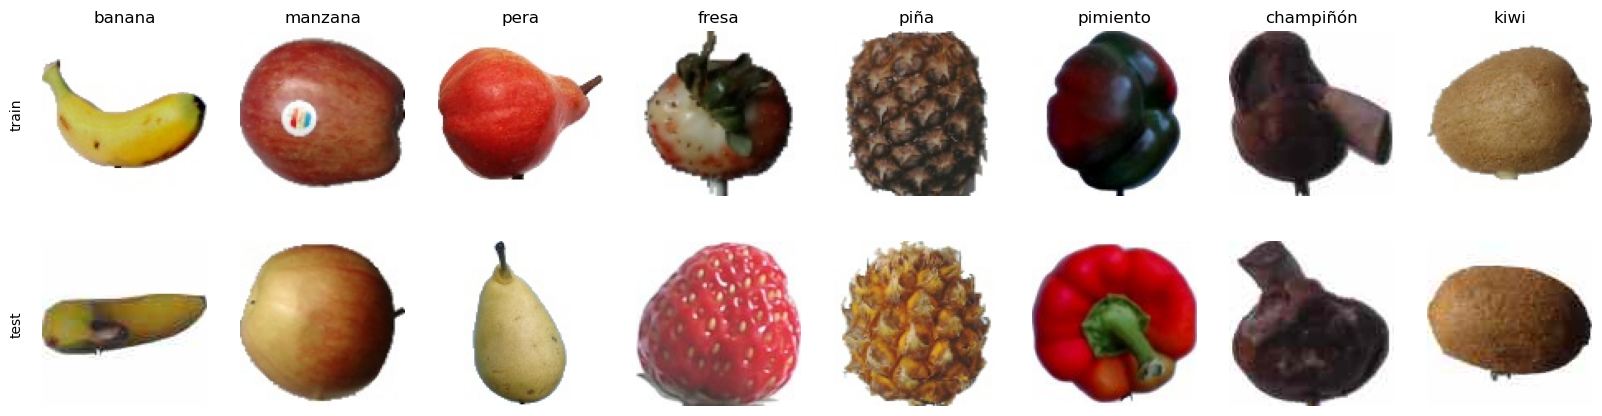

In [8]:
fig, ax = plt.subplots(2, len(CLASES), figsize=(20, 5))
for y in range(len(CLASES)):
    jtr = (ytr == y).nonzero()[0, 0].item()
    jte = (yte == y).nonzero()[0, 0].item()
    ax[0, y].imshow(Image.open(arch_tr[jtr]))
    ax[1, y].imshow(Image.open(arch_te[jte]))
    ax[0, y].set_title(CLASES[y])
    ax[0, y].axis('off')
    ax[1, y].axis('off')
ax[0, 0].text(-20, 50, 'train', rotation=90, va='center')
ax[1, 0].text(-20, 50, 'test', rotation=90, va='center')
plt.show()

## 3.- Mapa de profundidad con Depth Anything V2

Depth Anything V2 estima la profundidad a partir de una sola imagen. Usamos la versión Small (25 M de parámetros): https://huggingface.co/depth-anything/Depth-Anything-V2-Small-hf

El modelo se descarga una vez y queda en el caché local. También se guardan los mapas estimados para evitar procesar el dataset desde cero en cada ejecución.


In [9]:
modelo_prof = AutoModelForDepthEstimation.from_pretrained(
    'depth-anything/Depth-Anything-V2-Small-hf'
).to(DISP).eval()
print('Modelo de profundidad cargado.')

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

Modelo de profundidad cargado.


esta función recibe un lote de imágenes ell con forma (B, 3, ALTO, ANCHO) y valores en [0, 1], y devuelve un mapa de profundidad por imagen:

- agranda las imágenes a 518 × 518, el tamaño con el que se entrenó el modelo (tiene que ser múltiplo de 14, el tamaño de los parches del ViT)
- normaliza con la media y el desvío de ImageNet
- predice y vuelve a achicar el mapa al tamaño original

ojo: el modelo devuelve profundidad relativa e invertida, valores altos = cerca y valores bajos = lejos, y sin unidades

In [10]:
MEDIA = torch.tensor([0.485, 0.456, 0.406], device=DISP)[:, None, None]
DESV = torch.tensor([0.229, 0.224, 0.225], device=DISP)[:, None, None]

@torch.no_grad()
def profundidad(ell):
    x = F.interpolate(ell, size=(518, 518), mode='bicubic', align_corners=False)
    x = (x - MEDIA) / DESV
    d = modelo_prof(pixel_values=x).predicted_depth[:, None]
    return F.interpolate(d, size=ell.shape[-2:], mode='bilinear', align_corners=False)[:, 0]

esta función abre una lista de archivos y los convierte en un tensor (B, 3, ALTO, ANCHO) con valores en [0, 1]

In [11]:
def cargar(archivos):
    imagenes = np.stack([np.asarray(Image.open(f).convert('RGB')) for f in archivos])
    return torch.as_tensor(imagenes, device=DISP).permute(0, 3, 1, 2).float() / 255.0

el fondo es blanco, así que todo píxel con los tres canales por encima de 0.9 lo tomamos como fondo. binary_fill_holes rellena los huecos dentro del objeto, por ejemplo brillos blancos sobre la fruta

In [12]:
def mascara(ell):
    objeto = (ell.min(0).values < 0.9).cpu().numpy()
    return torch.as_tensor(binary_fill_holes(objeto), device=ell.device, dtype=torch.bool)

probamos con una foto de cada clase: imagen, mapa de profundidad (claro = cerca) y máscara del objeto

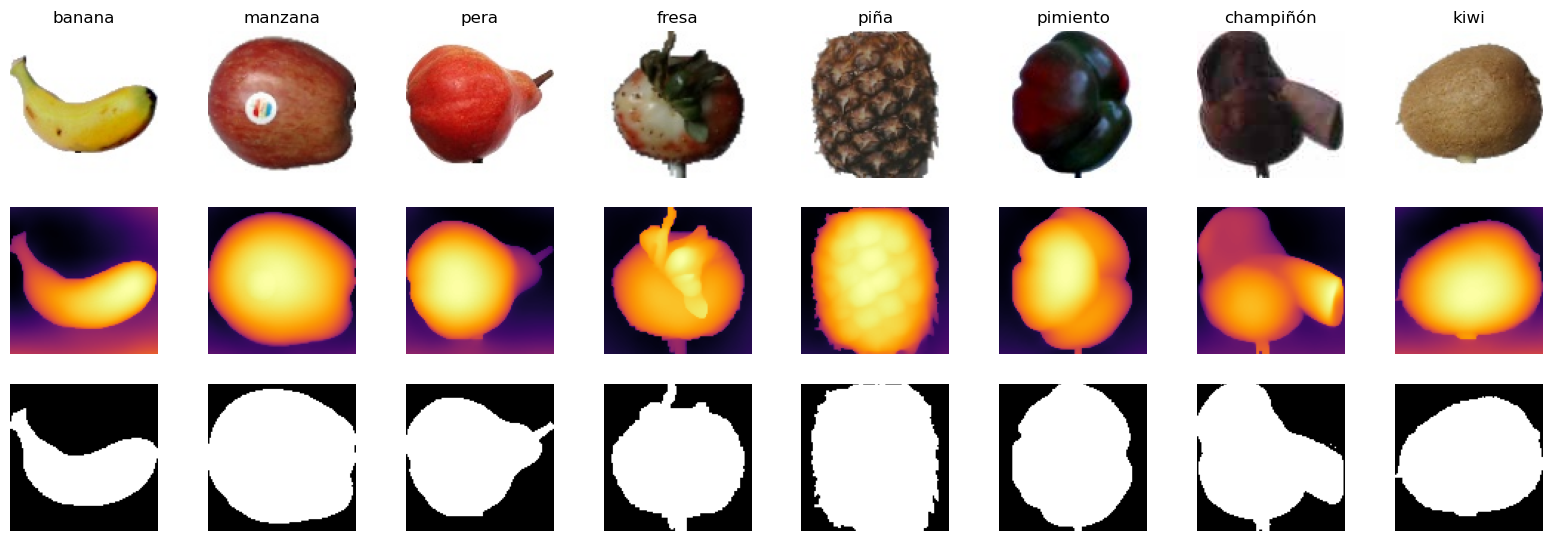

In [13]:
ejemplos_tr = [arch_tr[(ytr == y).nonzero()[0, 0].item()] for y in range(len(CLASES))]
ell_ej = cargar(ejemplos_tr)
d_ej = profundidad(ell_ej)
fig, ax = plt.subplots(3, len(CLASES), figsize=(20, 6.5))
for k in range(len(CLASES)):
    ax[0, k].imshow(ell_ej[k].permute(1, 2, 0).cpu())
    ax[0, k].set_title(CLASES[k])
    ax[1, k].imshow(d_ej[k].cpu(), cmap='inferno')
    ax[2, k].imshow(mascara(ell_ej[k]).cpu(), cmap='gray')
    for a_ in ax[:, k]:
        a_.axis('off')
plt.show()

## 4.- De profundidad a nube de puntos

Usamos el modelo pinhole: un píxel (m, n) con profundidad z corresponde al punto 3D

$$
X = \frac{(n-c_x)z}{a},\qquad
Y = \frac{(m-c_y)z}{b},\qquad Z=z.
$$

donde a y b son las distancias focales en píxeles y (c_x, c_y) el centro óptico. Tomamos las focales de la cámara de NYU Depth (518.9 y 519.5 para imágenes de 640 de ancho) escaladas a nuestro ancho. Como nuestras fotos son cuadradas, ponemos el centro óptico en el centro de la imagen

In [14]:
ALTO, ANCHO = 100, 100
escala = ANCHO / 640
a, b = 518.9 * escala, 519.5 * escala
c_x, c_y = ANCHO / 2, ALTO / 2

Depth Anything no da metros, así que construimos una profundidad aproximada:

- normalizamos la profundidad del objeto a [0, 1] (1 = punto más cercano)
- ubicamos el objeto a Z0 = 1 m de la cámara
- le damos un relieve igual a la mitad de su ancho, como una fruta redonda vista de frente, de la que solo vemos la mitad delantera

la escala exacta no importa mucho porque después normalizamos cada nube, lo que importa es la proporción entre el relieve y el ancho

In [15]:
Z0 = 1.0

def a_metros(d, m):
    if not m.any():
        raise ValueError('La máscara del objeto está vacía.')
    dn = (d - d[m].min()) / (d[m].max() - d[m].min() + 1e-6)        # 0 = lejos, 1 = cerca
    columnas = m.any(0).nonzero(as_tuple=False).flatten()
    ancho = (columnas.max() - columnas.min() + 1) * Z0 / a          # ancho del objeto en metros
    return Z0 + 0.5 * ancho * (1 - dn)

la función nube dibuja la nube con plotly, cada punto con el color de su píxel. Es la misma que vimos antes, pero recibe la máscara m para no dibujar el fondo

In [16]:
def nube(ell, z, m, paso=1):
    mm, nn_ = torch.meshgrid(torch.arange(ALTO, device=z.device),
                             torch.arange(ANCHO, device=z.device), indexing='ij')
    X = (nn_ - c_x) * z / a
    Y = (mm - c_y) * z / b
    sel = m[::paso, ::paso].reshape(-1)
    P = torch.stack([X, Y, z], -1)[::paso, ::paso].reshape(-1, 3)[sel].cpu().numpy()
    color = (ell.permute(1, 2, 0)[::paso, ::paso].reshape(-1, 3)[sel].cpu().numpy() * 255).astype(int)
    return go.Scatter3d(x=P[:, 0], y=P[:, 2], z=-P[:, 1], mode='markers',
                        marker=dict(size=1.5, color=[f'rgb({r},{g},{b_})' for r, g, b_ in color]))

el siguiente bloque deberia mostrar una fruta en nube de puntos

In [17]:
i = 0  # cambiar para ver otra clase
m = mascara(ell_ej[i])
fig = go.Figure(nube(ell_ej[i], a_metros(d_ej[i], m), m))
fig.update_layout(scene=dict(aspectmode='data'), height=500,
                  margin=dict(l=0, r=0, t=0, b=0))
fig.show()

para la red necesitamos nubes del mismo tamaño y en el rango [−1, 1], como las de ModelNet40. Esta función:

- calcula X, Y, Z de cada píxel del objeto, y guarda también su color
- elige 1024 puntos al azar (hay entre 2000 y 7000 píxeles de objeto por foto)
- centra la nube y la escala para que quepa en la esfera de radio 1

In [18]:
def a_nube(ell, d, N=1024):
    m = mascara(ell)
    z = a_metros(d, m)
    mm, nn_ = torch.meshgrid(torch.arange(ALTO, device=z.device),
                             torch.arange(ANCHO, device=z.device), indexing='ij')
    X = (nn_ - c_x) * z / a
    Y = (mm - c_y) * z / b
    P = torch.stack([X, Y, z], -1)[m]
    color = ell.permute(1, 2, 0)[m]
    if len(P) == 0:
        raise ValueError('No se detectaron píxeles del objeto.')
    sel = torch.randint(len(P), (N,), device=P.device)
    P, color = P[sel], color[sel]
    P = P - (P.max(0).values + P.min(0).values) / 2
    P = P / P.norm(dim=1).max().clamp_min(1e-6)
    return P, color

esta función procesa una lista de archivos por lotes: carga, estima profundidad y arma las nubes. Devuelve:

- X (B, 1024, 3) con las posiciones de los puntos
- C (B, 1024, 3) con sus colores
- I (B, 3, 64, 64) con las fotos achicadas, para la CNN 2D de la sección 7


**Procesamiento y almacenamiento de datos**

Se adaptó la función original para procesar las imágenes en lotes según la memoria disponible de la GPU. Además, se incorporó un sistema de caché que guarda los datos procesados y permite recuperarlos o continuar desde el último fragmento guardado. También se reutilizan los mapas de profundidad para los experimentos con menos puntos, evitando repetir cálculos costosos.


In [19]:
def procesar(archivos, lote=None, N=1024, guardar_imagenes=True, profundidades_existentes=None):
    """Procesa un fragmento, opcionalmente usando mapas de profundidad cacheados."""
    lote = LOTE_PROFUNDIDAD if lote is None else lote
    X, C, I, D = [], [], [], []
    for k in range(0, len(archivos), lote):
        ell = cargar(archivos[k:k + lote])
        if profundidades_existentes is None:
            d = profundidad(ell)
        else:
            d = profundidades_existentes[k:k+lote].to(DISP)
        if guardar_imagenes:
            I.append(F.interpolate(ell, size=(64, 64), mode='area').cpu())
        D.append(d.cpu())
        for e, dd in zip(ell, d):
            p, c = a_nube(e, dd, N=N)
            X.append(p.cpu())
            C.append(c.cpu())
    return {
        'X': torch.stack(X), 'C': torch.stack(C),
        'I': torch.cat(I) if guardar_imagenes else None,
        'D': torch.cat(D) if guardar_imagenes else None,
    }


def procesar_con_cache(archivos, nombre, N=1024, guardar_imagenes=True,
                       tomar_profundidad_de=None, trozo=128):
    """Reusa datos persistidos, o reanuda el preprocesamiento desde fragmentos.

    tomar_profundidad_de: nombre del split de 1024 puntos ya procesado;
    para 256 puntos reutiliza sus mapas de profundidad sin nueva inferencia.
    """
    firma = firma_archivos(archivos, N)
    destino = CARPETA_DATOS / f'{nombre}_N{N}_{firma}.pt'
    FIRMAS_DATOS[(nombre, N)] = firma

    if destino.exists() and not RECALCULAR_DATOS:
        print(f'[CACHÉ] {nombre}, N={N}: datos recuperados de {destino.name}')
        contenido = cargar_torch_seguro(destino)
    else:
        depth_cached = None
        if tomar_profundidad_de:
            firma_1024 = firma_archivos(archivos, 1024)
            origen_depth = CARPETA_DATOS / f'{tomar_profundidad_de}_N1024_{firma_1024}.pt'
            if origen_depth.exists() and not RECALCULAR_DATOS:
                depth_cached = cargar_torch_seguro(origen_depth)['D']
                print(f'[CACHÉ] Mapas de profundidad de {tomar_profundidad_de} reutilizados para N={N}')

        partes = []
        for inicio in range(0, len(archivos), trozo):
            fin = min(inicio + trozo, len(archivos))
            fragmento = CARPETA_DATOS / f'{nombre}_N{N}_{firma}_parte_{inicio:05d}.pt'
            if fragmento.exists() and not RECALCULAR_DATOS:
                parte = cargar_torch_seguro(fragmento)
            else:
                d_parte = depth_cached[inicio:fin] if depth_cached is not None else None
                parte = procesar(archivos[inicio:fin], N=N,
                                guardar_imagenes=guardar_imagenes,
                                profundidades_existentes=d_parte)
                guardar_torch_seguro(parte, fragmento)
                print(f'[GUARDADO] {nombre}, N={N}: {fin}/{len(archivos)} imágenes')
            partes.append(fragmento)

        trozos_cargados = [cargar_torch_seguro(p) for p in partes]
        contenido = {
            clave: (torch.cat([p[clave] for p in trozos_cargados])
                    if guardar_imagenes or clave in ('X', 'C') else None)
            for clave in ('X', 'C', 'I', 'D')
        }
        guardar_torch_seguro(contenido, destino)
        del trozos_cargados
        for p in partes:
            p.unlink(missing_ok=True)  # El archivo consolidado ya está guardado.
        print(f'[CACHÉ NUEVO] {nombre}, N={N}: {destino.name}')

    return (contenido['X'].to(DISP), contenido['C'].to(DISP),
            contenido['I'].to(DISP) if guardar_imagenes else None)

# Se usa una firma del dataset por split para impedir cargas accidentales de datos distintos.
FIRMAS_DATOS = {}

Procesamos todo el dataset. La primera vez puede tardar varios minutos; en las siguientes ejecuciones se recuperan los tensores guardados.


In [20]:
t0 = time.time()
Xtr, Ctr, Itr = procesar_con_cache(arch_tr, 'entrenamiento', N=1024)
Xte, Cte, Ite = procesar_con_cache(arch_te, 'test', N=1024)
ytr, yte = ytr.to(DISP), yte.to(DISP)
print('Entrenamiento:', tuple(Xtr.shape), '| Test:', tuple(Xte.shape),
      f'| tiempo: {time.time()-t0:.0f} s')
print('En futuras ejecuciones este paso recupera los tensores guardados.')

[CACHÉ] entrenamiento, N=1024: datos recuperados de entrenamiento_N1024_513ed214672d173d3737.pt
[CACHÉ] test, N=1024: datos recuperados de test_N1024_8114523806a06c6ecda9.pt
Entrenamiento: (4690, 1024, 3) | Test: (1974, 1024, 3) | tiempo: 2 s
En futuras ejecuciones este paso recupera los tensores guardados.


## 5. Voxelización con color

Es la misma función que vimos en la clase, con un cambio: si le pasamos los colores C, la grilla tiene 4 canales en lugar de 1

- canal 0: ocupado o no
- canales 1, 2 y 3: el color R, G, B del punto que cayó en ese cubo (si caen varios, queda uno de ellos)

recordar la formula para voxelizar:

$$i=\operatorname{clamp}\left(\left\lfloor \frac{P+1}{2}R \right\rfloor,0,R-1\right).$$


In [21]:
def voxelizar(P, R, C=None):
    i = (((P + 1) / 2) * R).floor().long().clamp(0, R - 1)
    V = torch.zeros(len(P), 1 if C is None else 4, R, R, R,
                    device=P.device, dtype=P.dtype)
    b_ = torch.arange(len(P), device=P.device)[:, None]
    V[b_, 0, i[..., 0], i[..., 1], i[..., 2]] = 1
    if C is not None:
        for c in range(3):
            V[b_, c + 1, i[..., 0], i[..., 1], i[..., 2]] = C[..., c]
    return V

vemos tres objetos voxelizados a 32³, pintando cada cubo con su color

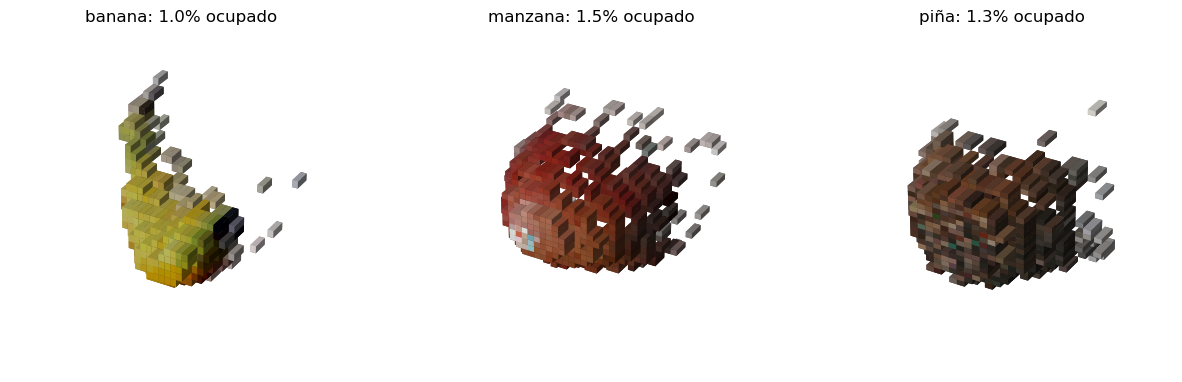

In [22]:
fig = plt.figure(figsize=(15, 5))
for k, y in enumerate([0, 1, 4]):
    j = (ytr == y).nonzero()[0, 0].item()
    V = voxelizar(Xtr[j:j + 1], 32, Ctr[j:j + 1])[0].cpu().numpy()
    ocupado = V[0].astype(bool).transpose(0, 2, 1)
    colores = V[1:].transpose(1, 3, 2, 0)
    ax = fig.add_subplot(1, 3, k + 1, projection='3d')
    ax.set_axis_off()
    ax.voxels(ocupado[:, :, ::-1], facecolors=colores[:, :, ::-1])
    ax.set_title(f'{CLASES[y]}: {ocupado.mean():.1%} ocupado')
plt.show()

la nube es solo la cara que ve la cámara: una "cáscara" 2.5D, no el objeto completo como en ModelNet40. Por eso ocupa todavía menos cubos

## 6. Aumento de datos y entrenamiento

deforma un poco la nube de cada objeto, igual que en la clase: escala al azar por eje (80 % a 120 %) y desplaza ±0.1

In [23]:
def aumentar_puntos(P):
    escala_p = torch.empty(len(P), 1, 3, device=P.device).uniform_(0.8, 1.2)
    traslado = torch.empty(len(P), 1, 3, device=P.device).uniform_(-0.1, 0.1)
    return (P * escala_p + traslado).clamp(-1, 1)

cambia un poco los colores de cada objeto, para que la red no dependa del tono exacto de las frutas de entrenamiento:

- brillo: multiplica los tres canales por un mismo número entre 0.7 y 1.3 (más luz o menos luz)
- tono: multiplica cada canal por un número distinto entre 0.8 y 1.2 (la fruta queda un poco más roja, verde o amarilla)

recibe colores con forma (B, N, 3)

In [24]:
def aumentar_color(C):
    brillo = torch.empty(len(C), 1, 1, device=C.device).uniform_(0.7, 1.3)
    tono = torch.empty(len(C), 1, 3, device=C.device).uniform_(0.8, 1.2)
    return (C * brillo * tono).clamp(0, 1)

bucle de entrenamiento común para las tres redes:

- tr y te son tuplas (entrada_1, ..., etiquetas), así la misma función sirve para nubes y para imágenes
- red recibe las entradas y aum=True cuando hay que aumentar los datos (solo al entrenar)
- devuelve las predicciones finales en test, para compararlas por clase

recuerda que los modulos son los modelos que entrenaremos

El entrenamiento guarda un checkpoint al terminar cada época (pesos, optimizador y accuracy de test). Si se interrumpe, puede continuar desde el último guardado. Si el modelo ya terminó de entrenarse, se recupera directamente.

Para repetir los entrenamientos desde cero, usar `REENTRENAR_MODELOS=True`. Se mantiene el conjunto de test para seguir la consigna, aunque para elegir la mejor época sería preferible contar con un conjunto de validación independiente.


In [25]:
def a_cpu(objeto):
    """Copia recursivamente los tensores a CPU para tener un checkpoint portable."""
    if torch.is_tensor(objeto):
        return objeto.detach().cpu().clone()
    if isinstance(objeto, dict):
        return {k: a_cpu(v) for k, v in objeto.items()}
    if isinstance(objeto, (list, tuple)):
        return type(objeto)(a_cpu(x) for x in objeto)
    return objeto


def entrenar(red, modulos, tr, te, epocas=15, lote=None,
            usar_aumento=True, devolver_historial=False, id_guardado=None,
            firma_datos=None):
    lote = LOTE_ENTRENAMIENTO if lote is None else lote
    *ent_tr, y_tr = tr
    *ent_te, y_te = te
    opt = torch.optim.Adam(modulos.parameters(), lr=1e-3)
    historial, pred, inicio = [], None, 0
    t0 = time.time()
    ruta = CARPETA_MODELOS / f'{id_guardado}.pt' if id_guardado else None
    meta = {'id': id_guardado or '', 'version': VERSION_MODELO,
            'datos': str(firma_datos), 'clases': list(CLASES),
            'usar_aumento': usar_aumento, 'lote': lote, 'lr': 1e-3}

    if ruta is not None and ruta.exists() and not (REENTRENAR_MODELOS or RECALCULAR_DATOS):
        guardado = cargar_torch_seguro(ruta)
        if guardado.get('meta') == meta:
            modulos.load_state_dict(guardado['modelo'])
            opt.load_state_dict(guardado['optimizador'])
            inicio = int(guardado['epoca'])
            historial = list(guardado['historial'])
            pred = guardado['pred'].to(DISP)
            if 'rng_cpu' in guardado:
                torch.set_rng_state(guardado['rng_cpu'])
            if torch.cuda.is_available() and 'rng_cuda' in guardado:
                torch.cuda.set_rng_state_all(guardado['rng_cuda'])
            if inicio > epocas:
                raise ValueError('El checkpoint contiene más épocas que las solicitadas; '
                                 'usá otro id_guardado o REENTRENAR_MODELOS=True.')
            if inicio == epocas:
                print(f'[MODELO RECUPERADO] {id_guardado}: {inicio} épocas; sin reentrenamiento.')
                return (pred, historial[:epocas]) if devolver_historial else pred
            print(f'[MODELO REANUDADO] {id_guardado}: desde época {inicio+1}/{epocas}')
        else:
            print(f'[AVISO] Checkpoint {ruta.name} no coincide con la configuración; se entrena desde cero.')

    for epoca in range(inicio, epocas):
        modulos.train()
        for b_ in torch.randperm(len(y_tr), device=y_tr.device).split(lote):
            logits = red(*[e[b_] for e in ent_tr], aum=usar_aumento)
            perdida = F.cross_entropy(logits, y_tr[b_])
            opt.zero_grad(set_to_none=True)
            perdida.backward()
            opt.step()

        modulos.eval()
        with torch.no_grad():
            pred = torch.cat([
                red(*[e[k:k+lote] for e in ent_te]).argmax(1)
                for k in range(0, len(y_te), lote)
            ])
        acc = pred.eq(y_te).float().mean().item()
        historial.append(acc)
        print(f'Época {epoca+1:2d}/{epocas} | accuracy test {acc:.3f}')

        if ruta is not None:
            paquete = {
                'meta': meta, 'epoca': epoca+1, 'historial': historial,
                'modelo': a_cpu(modulos.state_dict()),
                'optimizador': a_cpu(opt.state_dict()),
                'pred': pred.detach().cpu(),
                'rng_cpu': torch.get_rng_state().clone(),
                'rng_cuda': [r.clone() for r in torch.cuda.get_rng_state_all()]
                            if torch.cuda.is_available() else [],
            }
            guardar_torch_seguro(paquete, ruta)

    print(f'{(time.time()-t0)/max(epocas-inicio,1):.1f} s por época calculada')
    if ruta is not None:
        print(f'[GUARDADO] Modelo: {ruta.resolve()}')
    return (pred, historial) if devolver_historial else pred

bloque básico y red 3D:

- tres bloques 32³ -> 16³ -> 8³ -> 4³, igual que en la clase
- cin es la cantidad de canales de entrada

In [26]:
def bloque(cin, cout):
    return [
        nn.Conv3d(cin, cout, kernel_size=3, padding=1),
        nn.BatchNorm3d(cout),
        nn.ReLU(inplace=True),
        nn.MaxPool3d(kernel_size=2),
    ]

def crear_cnn(cin):
    return nn.Sequential(
        *bloque(cin, 32),
        *bloque(32, 64),
        *bloque(64, 128),
        nn.AdaptiveMaxPool3d(1),
        nn.Flatten(),
        nn.Dropout(0.5),
        nn.Linear(128, len(CLASES)),
    ).to(DISP)

CNN 3D, solo forma: 1 canal, ocupado o no

la red ignora los colores

In [27]:
cnn_forma = crear_cnn(1)

def solo_forma(P, C, aum=False):
    if aum:
        P = aumentar_puntos(P)
    return cnn_forma(voxelizar(P, 32))

pred_forma, hist_forma = entrenar(
    solo_forma, cnn_forma,
    (Xtr, Ctr, ytr), (Xte, Cte, yte),
    devolver_historial=True, id_guardado='cnn_3d_forma_1024',
    firma_datos=(FIRMAS_DATOS[('entrenamiento', 1024)], FIRMAS_DATOS[('test', 1024)])
)

[MODELO RECUPERADO] cnn_3d_forma_1024: 15 épocas; sin reentrenamiento.


CNN 3D, forma y color: 4 canales, con aumento de puntos y de color

In [28]:
def crear_clasificador_color():
    """Modelo independiente para cada ensayo (sin compartir pesos entre pruebas)."""
    modelo = crear_cnn(4)

    def clasificador(P, C, aum=False):
        if aum:
            P, C = aumentar_puntos(P), aumentar_color(C)
        return modelo(voxelizar(P, 32, C))

    return modelo, clasificador

cnn_color, forma_color = crear_clasificador_color()
pred_color, hist_color = entrenar(
    forma_color, cnn_color,
    (Xtr, Ctr, ytr), (Xte, Cte, yte),
    devolver_historial=True, id_guardado='cnn_3d_color_1024',
    firma_datos=(FIRMAS_DATOS[('entrenamiento', 1024)], FIRMAS_DATOS[('test', 1024)])
)
accuracy_original = pred_color.eq(yte).float().mean().item()
print('Accuracy actual 3D forma+color:', f'{accuracy_original:.3%}')

[MODELO RECUPERADO] cnn_3d_color_1024: 15 épocas; sin reentrenamiento.
Accuracy actual 3D forma+color: 73.354%


## 7.- CNN 2D de referencia y comparación

cuánto aporta pasar por 3D? lo medimos con una CNN 2D con la misma estructura (tres bloques, pooling global y una capa lineal), que mira directamente la foto de 64 × 64

el aumento de datos es el mismo de color, más un espejo horizontal al azar

In [29]:
def aumentar_imagen(I):
    B, _, H, W = I.shape
    I = torch.where(torch.rand(B, 1, 1, 1, device=I.device) < 0.5, I.flip(3), I)
    C = aumentar_color(I.permute(0, 2, 3, 1).reshape(B, -1, 3))
    return C.reshape(B, H, W, 3).permute(0, 3, 1, 2)

def bloque2d(cin, cout):
    return [
        nn.Conv2d(cin, cout, kernel_size=3, padding=1),
        nn.BatchNorm2d(cout),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(kernel_size=2),
    ]

cnn_2d = nn.Sequential(
    *bloque2d(3, 32),
    *bloque2d(32, 64),
    *bloque2d(64, 128),
    nn.AdaptiveMaxPool2d(1),
    nn.Flatten(),
    nn.Dropout(0.5),
    nn.Linear(128, len(CLASES)),
).to(DISP)

def imagen_2d(I, aum=False):
    if aum:
        I = aumentar_imagen(I)
    return cnn_2d(I)

pred_2d, hist_2d = entrenar(
    imagen_2d, cnn_2d,
    (Itr, ytr), (Ite, yte),
    devolver_historial=True, id_guardado='cnn_2d_rgb',
    firma_datos=(FIRMAS_DATOS[('entrenamiento', 1024)], FIRMAS_DATOS[('test', 1024)])
)

[MODELO RECUPERADO] cnn_2d_rgb: 15 épocas; sin reentrenamiento.


accuracy por clase de los tres modelos, sobre las variedades que nunca vieron

In [30]:
modelos = {'3D forma': pred_forma, '3D forma+color': pred_color, '2D imagen': pred_2d}
print(f"{'Clase':12s}" + ''.join(f'{nombre:>17s}' for nombre in modelos))
for y, clase in enumerate(CLASES):
    s = yte == y
    print(f'{clase:12s}' + ''.join(
        f'{p[s].eq(y).float().mean().item():>17.1%}' for p in modelos.values()
    ))
print(f"{'TOTAL':12s}" + ''.join(
    f'{p.eq(yte).float().mean().item():>17.1%}' for p in modelos.values()
))

Clase                3D forma   3D forma+color        2D imagen
banana                 100.0%           100.0%           100.0%
manzana                 64.8%           100.0%           100.0%
pera                    98.0%            70.8%           100.0%
fresa                   34.4%           100.0%           100.0%
piña                     5.2%            12.8%            89.2%
pimiento                14.0%           100.0%            98.0%
champiñón               75.2%           100.0%           100.0%
kiwi                    82.0%             6.0%            25.2%
TOTAL                   58.7%            73.4%            88.9%


matriz de confusión de cada modelo: cada fila es la clase real y cada columna la predicha. Lo que cae fuera de la diagonal son errores

Matriz guardada en: C:\Users\tolot\Documents\UBA\2026\5B\VPC3D\artefactos_frutas3d\resultados\matrices_confusion.png


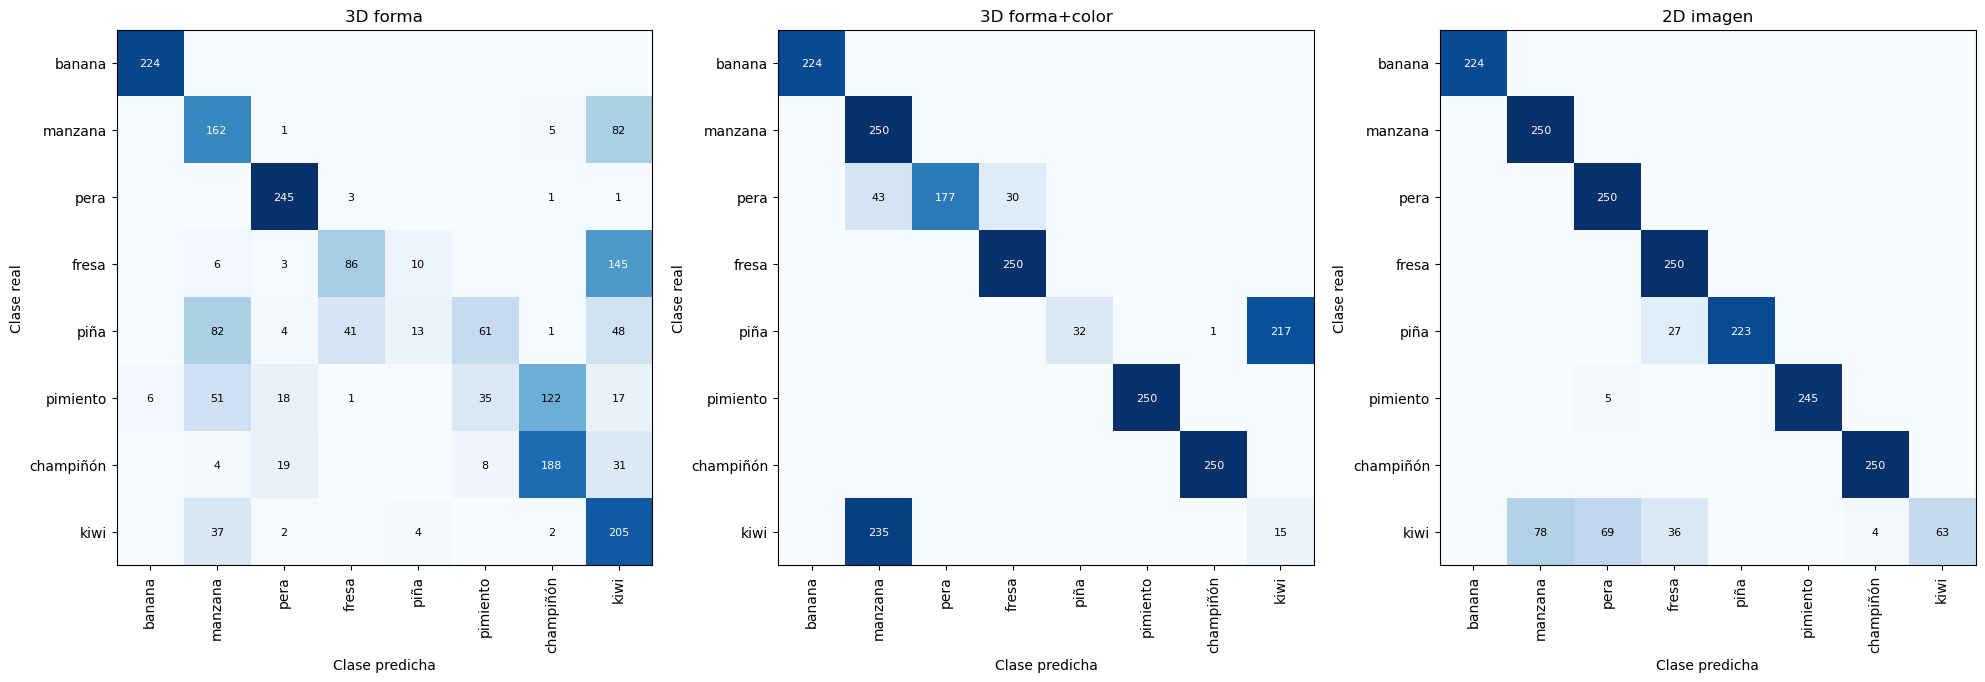

In [31]:
fig, ax = plt.subplots(1, 3, figsize=(20, 6.5))
matrices = {}
for k, (nombre, pred) in enumerate(modelos.items()):
    M = torch.bincount((yte.cpu() * len(CLASES) + pred.cpu()).long(),
                       minlength=len(CLASES)**2).reshape(len(CLASES), len(CLASES))
    matrices[nombre] = M
    ax[k].imshow(M, cmap='Blues')
    for r in range(len(CLASES)):
        for q in range(len(CLASES)):
            valor = M[r, q].item()
            if valor:
                ax[k].text(q, r, str(valor), ha='center', va='center', fontsize=8,
                           color='white' if valor > M.max().item()/2 else 'black')
    ax[k].set_xticks(range(len(CLASES)), CLASES, rotation=90)
    ax[k].set_yticks(range(len(CLASES)), CLASES)
    ax[k].set_title(nombre)
    ax[k].set_xlabel('Clase predicha')
    ax[k].set_ylabel('Clase real')
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / 'matrices_confusion.png', dpi=160, bbox_inches='tight')
print('Matriz guardada en:', (CARPETA_RESULTADOS / 'matrices_confusion.png').resolve())
plt.show()

### Interpretación de las matrices de confusión

In [32]:
resumen_modelos = {}
for nombre, M in matrices.items():
    fuera_diag = M.clone()
    fuera_diag.fill_diagonal_(0)
    i, j = divmod(fuera_diag.argmax().item(), len(CLASES))
    aciertos, total = M.trace().item(), M.sum().item()
    print(f'{nombre}: {aciertos}/{total} aciertos '
          f'({aciertos/total:.1%}). Confusión predominante: '
          f'{CLASES[i]} → {CLASES[j]} ({fuera_diag[i,j].item()} casos).')
    resumen_modelos[nombre] = {
        'accuracy': aciertos / total,
        'aciertos': aciertos, 'total': total,
        'accuracy_por_clase': {
            clase: float(M[z,z] / M[z].sum()) for z, clase in enumerate(CLASES)
        },
        'confusion_matriz': M.tolist(),
        'principal_confusion': {'real': CLASES[i], 'predicha': CLASES[j],
                                'casos': int(fuera_diag[i,j])},
    }
guardar_json_seguro({'clases': CLASES, 'modelos': resumen_modelos},
                   CARPETA_RESULTADOS / 'evaluacion_modelos.json')
print('Evaluación persistida en evaluacion_modelos.json')

3D forma: 1158/1974 aciertos (58.7%). Confusión predominante: fresa → kiwi (145 casos).
3D forma+color: 1448/1974 aciertos (73.4%). Confusión predominante: kiwi → manzana (235 casos).
2D imagen: 1755/1974 aciertos (88.9%). Confusión predominante: kiwi → manzana (78 casos).
Evaluación persistida en evaluacion_modelos.json


**Interpretación de las matrices de confusión**

La **CNN 2D** obtuvo el mejor resultado en las 1.974 imágenes de test, con **88,91 %** de accuracy. Le siguió la **CNN 3D con forma y color**, con **73,35 %**, y por último la **CNN 3D de solo forma**, con **58,66 %**. El color aportó bastante información a la representación 3D. La diferencia respecto de usar solo la forma fue de casi 15 puntos porcentuales. De todas formas, para estas imágenes, la red 2D clasificó mejor sin necesidad de estimar profundidad ni construir vóxeles.

Las matrices muestran que los errores se concentran en algunas clases. La CNN 3D de solo forma confundió principalmente **fresa con kiwi** (145 imágenes). En la CNN 3D con color, el mayor problema fue **kiwi clasificado como manzana** (235 imágenes). Además, solo reconoció correctamente el **6 %** de los kiwis y el **12,8 %** de las piñas. La CNN 2D también confundió kiwi con manzana (78 imágenes), aunque en general tuvo menos errores. Esto deja claro que una accuracy global alta no implica que todas las clases se reconozcan igual de bien. Una posible limitación del enfoque 3D es que la profundidad estimada a partir de una foto representa solo la superficie visible y puede perder información al convertirla en vóxeles.


predicciones de la CNN 3D con color en 8 objetos de test

en verde si acierta y en rojo si falla, con las 3 clases más probables

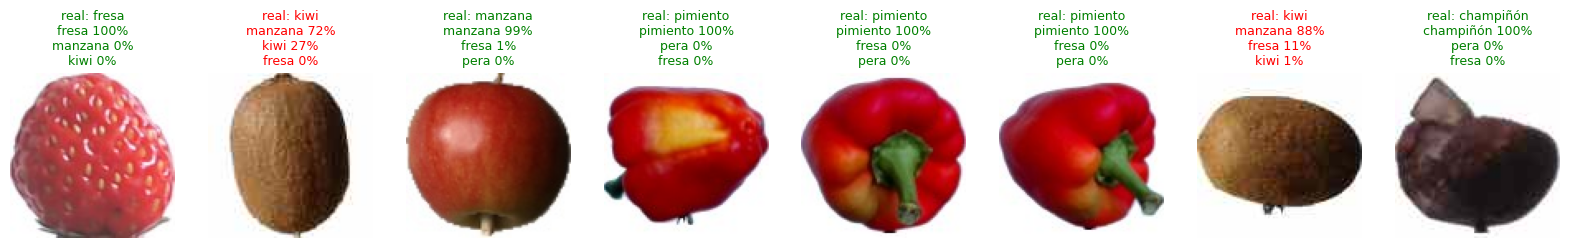

In [33]:
cnn_color.eval()
ejemplos_idx = torch.randperm(len(Xte), device=DISP)[:8]
with torch.no_grad():
    prob = F.softmax(forma_color(Xte[ejemplos_idx], Cte[ejemplos_idx]), dim=1)

fig, ax = plt.subplots(1, 8, figsize=(20, 3.5))
for k, indice in enumerate(ejemplos_idx.tolist()):
    top_p, top_c = prob[k].topk(3)
    acierto = top_c[0].item() == yte[indice].item()
    ax[k].imshow(Image.open(arch_te[indice]))
    ax[k].axis('off')
    etiquetas = '\n'.join(f'{CLASES[int(c)]} {float(v):.0%}' for v, c in zip(top_p, top_c))
    ax[k].set_title(f'real: {CLASES[int(yte[indice])]}\n{etiquetas}',
                    fontsize=9, color='green' if acierto else 'red')
plt.show()

## 8.- Probar con imágenes propias

Para que una foto propia se parezca a las del dataset:
- la recortamos al objeto (todo lo que no es blanco)
- le agregamos un margen blanco y la dejamos cuadrada
- la achicamos a 100 × 100

Funciona mejor con una sola fruta o verdura de estas 8 clases, centrada y sobre fondo blanco liso.

En este caso se usan cuatro fotografías tomadas en entornos cotidianos, para observar cómo responden los modelos ante imágenes distintas de Fruits-360.


In [34]:
def preparar(ruta, margen=0.05):
    img = np.array(Image.open(ruta).convert('RGB'), copy=True)
    objeto = img.min(2) < 230
    filas, cols = np.where(objeto)
    if len(filas) == 0:
        raise ValueError('No se detectó un objeto distinto del fondo blanco.')
    img = img[filas.min():filas.max() + 1, cols.min():cols.max() + 1]
    lado = max(1, int(max(img.shape[:2]) * (1 + 2 * margen)))
    lienzo = np.full((lado, lado, 3), 255, dtype=np.uint8)
    f0, c0 = (lado - img.shape[0]) // 2, (lado - img.shape[1]) // 2
    lienzo[f0:f0 + img.shape[0], c0:c0 + img.shape[1]] = img
    img = np.array(Image.fromarray(lienzo).resize((ANCHO, ALTO), Image.Resampling.BICUBIC), copy=True)
    return torch.as_tensor(img, device=DISP).permute(2, 0, 1).float() / 255


esta función hace todo el recorrido para una foto: preparar, profundidad, nube, voxelizar y clasificar con las dos redes 3D y con la 2D

muestra la foto, el mapa de profundidad y las 3 clases más probables de cada red, y devuelve la figura de la nube

In [35]:
def clasificar(ruta, devolver_predicciones=False, guardar_grafico=None):
    ell = preparar(ruta)
    d = profundidad(ell[None])[0]
    P, C = a_nube(ell, d)
    I = F.interpolate(ell[None], size=(64, 64), mode='area')
    for red in [cnn_forma, cnn_color, cnn_2d]:
        red.eval()

    with torch.no_grad():
        logits = {'3D forma': solo_forma(P[None], C[None]),
                  '3D forma+color': forma_color(P[None], C[None]),
                  '2D imagen': imagen_2d(I)}

    fig, ax = plt.subplots(1, 2 + len(logits), figsize=(14, 3))
    ax[0].imshow(ell.permute(1, 2, 0).cpu())
    ax[0].set_title('Foto')
    ax[1].imshow(d.cpu(), cmap='inferno')
    ax[1].set_title('Profundidad')
    for k, (nombre, salida) in enumerate(logits.items()):
        top_p, top_c = F.softmax(salida, dim=1)[0].topk(3)
        resumen = '\n'.join(f'{CLASES[int(c)]}: {float(v):.0%}' for v, c in zip(top_p, top_c))
        ax[k + 2].text(0, 0.5, f'{nombre}\n\n{resumen}', va='center', fontsize=10)
    for a_ in ax:
        a_.axis('off')
    if guardar_grafico is not None:
        fig.savefig(guardar_grafico, dpi=160, bbox_inches='tight')
    plt.show()

    m = mascara(ell)
    fig = go.Figure(nube(ell, a_metros(d, m), m))
    fig.update_layout(scene=dict(aspectmode='data'), height=400,
                      margin=dict(l=0, r=0, t=0, b=0))
    if devolver_predicciones:
        resultados = {}
        for nombre, salida in logits.items():
            probabilidades = F.softmax(salida, dim=1)[0].detach().cpu()
            valores, indices = probabilidades.topk(3)
            resultados[nombre] = {
                'predicha': CLASES[int(indices[0])],
                'confianza': float(valores[0]),
                'top_3': [
                    {'clase': CLASES[int(j)], 'probabilidad': float(v)}
                    for v, j in zip(valores, indices)
                ],
            }
        return fig, resultados
    return fig


primero lo probamos con una foto de test del dataset

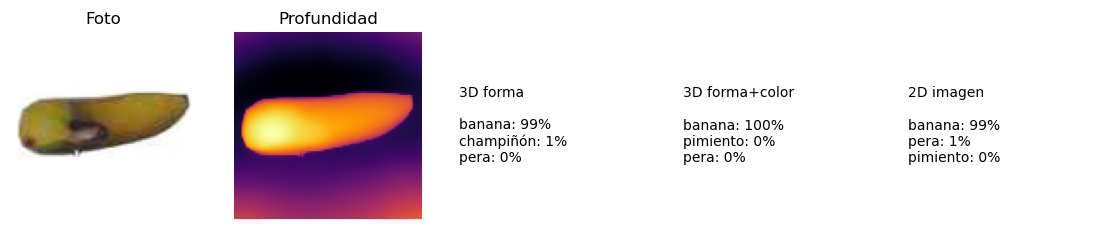

In [36]:
clasificar(arch_te[0]).show()

### Prueba con fotografías externas


Se utilizan cuatro imágenes: una banana sobre granito, un kiwi sobre una mesada, una pera sobre un fondo oscuro y un pimiento sobre una tabla de cocina. Se encuentran en la carpeta `fotos_reales/`.

Cada imagen se clasifica de dos maneras: primero con el preprocesamiento original, pensado para fondos blancos, y después reemplazando el fondo por blanco mediante **GrabCut**. Se muestra la máscara obtenida para poder revisar qué partes del objeto se conservaron.


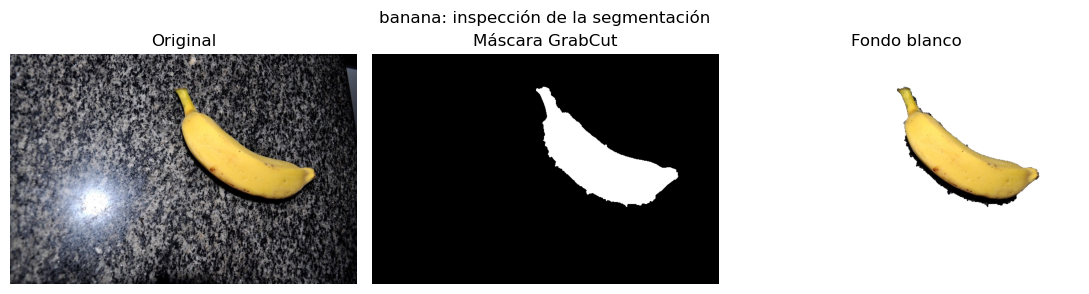


BANANA — original


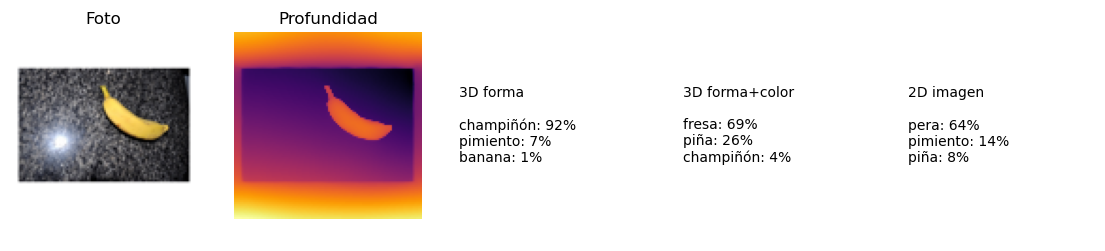


BANANA — segmentada


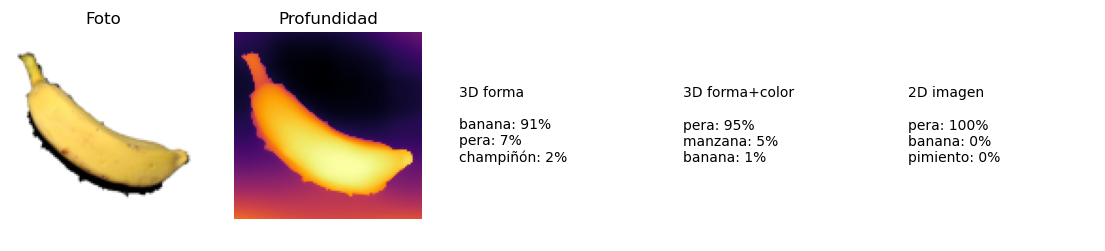

3D forma         : champiñón    → banana        (real: banana)
3D forma+color   : fresa        → pera          (real: banana)
2D imagen        : pera         → pera          (real: banana)


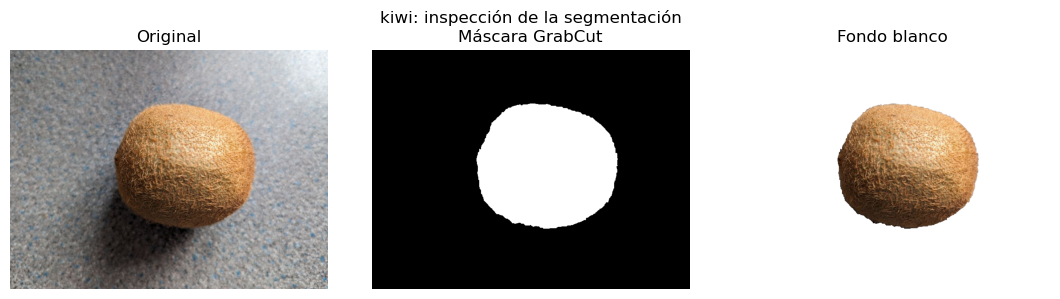


KIWI — original


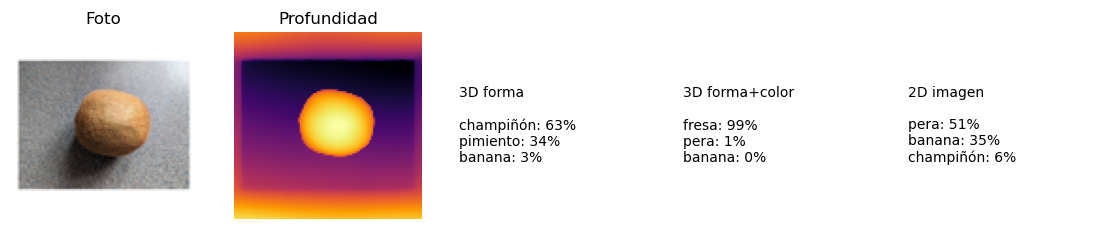


KIWI — segmentada


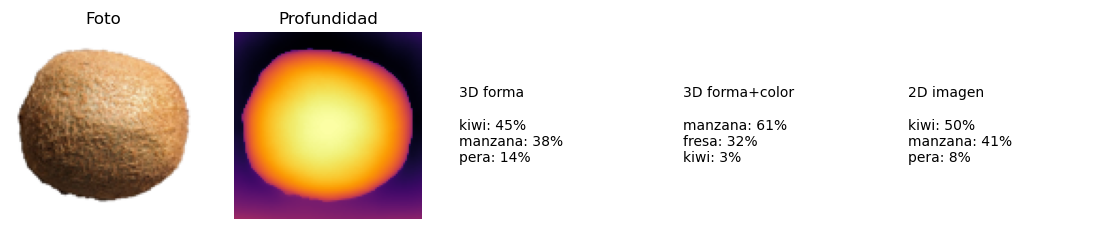

3D forma         : champiñón    → kiwi          (real: kiwi)
3D forma+color   : fresa        → manzana       (real: kiwi)
2D imagen        : pera         → kiwi          (real: kiwi)


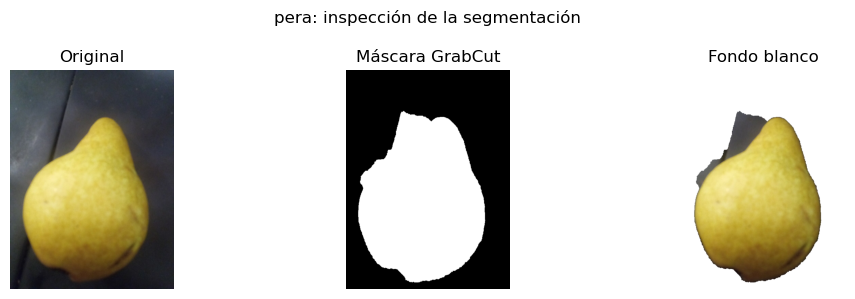


PERA — original


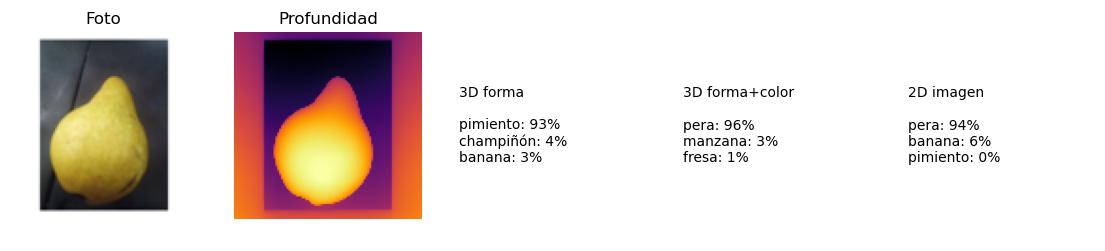


PERA — segmentada


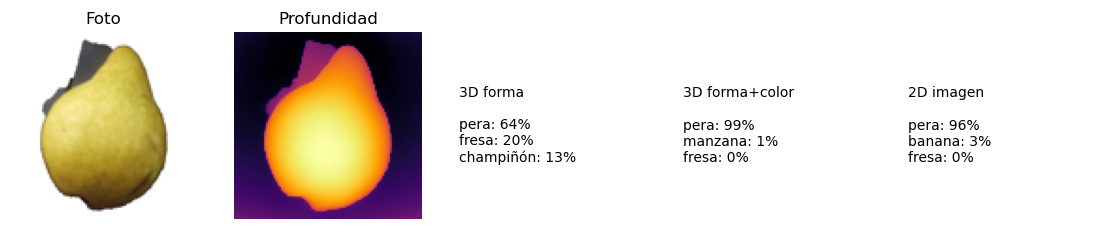

3D forma         : pimiento     → pera          (real: pera)
3D forma+color   : pera         → pera          (real: pera)
2D imagen        : pera         → pera          (real: pera)


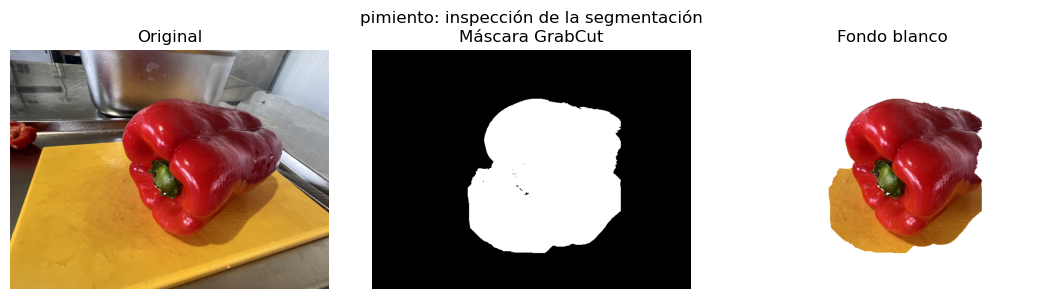


PIMIENTO — original


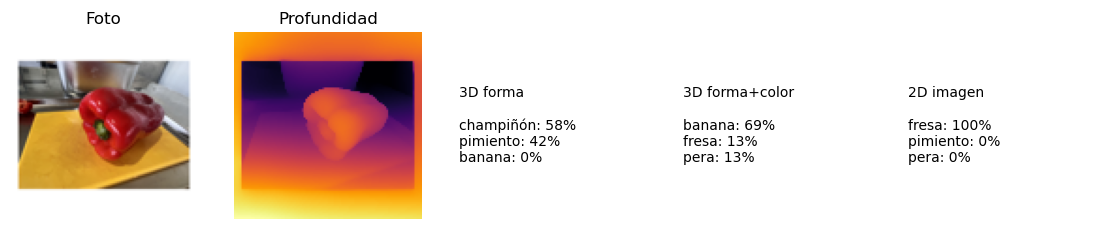


PIMIENTO — segmentada


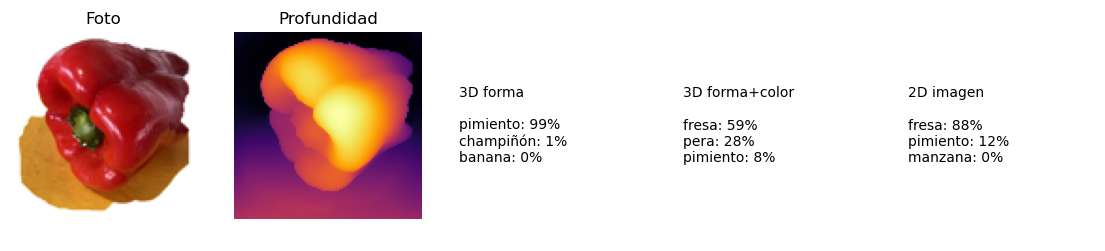

3D forma         : champiñón    → pimiento      (real: pimiento)
3D forma+color   : banana       → fresa         (real: pimiento)
2D imagen        : fresa        → fresa         (real: pimiento)
Resultados guardados: C:\Users\tolot\Documents\UBA\2026\5B\VPC3D\artefactos_frutas3d\resultados\cuatro_fotos_reales.json


In [37]:
import cv2

# Restaurar las focales si se ejecutó una versión anterior de esta celda.
escala_camara = ANCHO / 640
a, b = 518.9 * escala_camara, 519.5 * escala_camara

CARPETA_EXTERNAS = Path('fotos_reales')
FOTOS_EXTERNAS = [
    ('banana', 'banana.jpg', (0.43, 0.06, 0.92, 0.71)),
    ('kiwi', 'kiwi.jpg', (0.29, 0.17, 0.84, 0.82)),
    ('pera', 'pera.jpg', (0.04, 0.16, 0.90, 0.97)),
    ('pimiento', 'pimiento.jpeg', (0.25, 0.16, 0.78, 0.85)),
]


def quitar_fondo(ruta, destino, caja):
    """GrabCut con rectángulo aproximado; devuelve la máscara del primer plano."""
    imagen = Image.open(ruta).convert('RGB')
    imagen.thumbnail((700, 700))
    rgb = np.array(imagen)
    alto, ancho = rgb.shape[:2]
    x0, y0, x1, y1 = caja
    rect = (int(x0 * ancho), int(y0 * alto),
            int((x1 - x0) * ancho), int((y1 - y0) * alto))
    mascara_gc = np.zeros((alto, ancho), np.uint8)
    cv2.grabCut(cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR), mascara_gc, rect,
                np.zeros((1, 65), np.float64), np.zeros((1, 65), np.float64),
                5, cv2.GC_INIT_WITH_RECT)
    objeto = ((mascara_gc == cv2.GC_FGD) | (mascara_gc == cv2.GC_PR_FGD)).astype('uint8')
    n, etiquetas, areas, _ = cv2.connectedComponentsWithStats(objeto, connectivity=8)
    if n < 2:
        raise ValueError(f'GrabCut no encontró la fruta en {ruta.name}')
    objeto = etiquetas == (1 + int(np.argmax(areas[1:, cv2.CC_STAT_AREA])))
    Image.fromarray(np.where(objeto[:, :, None], rgb, 255).astype('uint8')).save(destino)
    return objeto


resultados_reales = []
for clase_real, archivo, caja in FOTOS_EXTERNAS:
    ruta = CARPETA_EXTERNAS / archivo
    if not ruta.is_file():
        raise FileNotFoundError(f'Falta {ruta}. Revisá la carpeta fotos_reales junto al notebook.')
    ruta_seg = CARPETA_EXTERNAS / (Path(archivo).stem + '_segmentada.png')
    mascara_grabcut = quitar_fondo(ruta, ruta_seg, caja)

    fig, ax = plt.subplots(1, 3, figsize=(11, 3))
    ax[0].imshow(Image.open(ruta)); ax[0].set_title('Original')
    ax[1].imshow(mascara_grabcut, cmap='gray'); ax[1].set_title('Máscara GrabCut')
    ax[2].imshow(Image.open(ruta_seg)); ax[2].set_title('Fondo blanco')
    for eje in ax: eje.axis('off')
    fig.suptitle(f'{clase_real}: inspección de la segmentación')
    plt.tight_layout()
    plt.show()

    predicciones = {}
    for nombre, foto in [('original', ruta), ('segmentada', ruta_seg)]:
        print(f'\n{clase_real.upper()} — {nombre}')
        figura, pred = clasificar(foto, devolver_predicciones=True)
        figura.show()
        predicciones[nombre] = pred
    for nombre_modelo in predicciones['original']:
        pred_original = predicciones['original'][nombre_modelo]['predicha']
        pred_segmentada = predicciones['segmentada'][nombre_modelo]['predicha']
        print(f'{nombre_modelo:17s}: {pred_original:12s} → {pred_segmentada:12s}  (real: {clase_real})')
    resultados_reales.append({
        'clase_real': clase_real, 'archivo': archivo, 'predicciones': predicciones,
    })

guardar_json_seguro(resultados_reales, CARPETA_RESULTADOS / 'cuatro_fotos_reales.json')
print('Resultados guardados:', (CARPETA_RESULTADOS / 'cuatro_fotos_reales.json').resolve())


### Resultados con las cuatro fotografías

Se probaron las mismas tres redes con las fotos originales y con las versiones segmentadas. Las predicciones obtenidas fueron:

| Imagen | Modelo | Original | Fondo eliminado |
|---|---|---|---|
| Banana | 3D forma | champiñón | **banana** |
| Banana | 3D forma+color | fresa | pera |
| Banana | 2D imagen | pera | pera |
| Kiwi | 3D forma | champiñón | **kiwi** |
| Kiwi | 3D forma+color | fresa | fresa |
| Kiwi | 2D imagen | pera | **kiwi** |
| Pera | 3D forma | pimiento | champiñón |
| Pera | 3D forma+color | **pera** | **pera** |
| Pera | 2D imagen | **pera** | **pera** |
| Pimiento | 3D forma | champiñón | **pimiento** |
| Pimiento | 3D forma+color | banana | fresa |
| Pimiento | 2D imagen | fresa | fresa |

Con las imágenes originales hubo **2 aciertos sobre 12 predicciones**, mientras que al eliminar el fondo hubo **6 sobre 12**. La mejora más clara apareció en la CNN 3D de solo forma: pasó de no acertar ninguna de las cuatro fotos a reconocer banana, kiwi y pimiento. La red 2D también pasó a reconocer el kiwi, pero la CNN 3D con color siguió acertando únicamente la pera. Por lo tanto, quitar el fondo ayudó en algunos casos, aunque no resolvió todos los errores.

Al revisar las máscaras, banana y kiwi quedaron bastante bien separados, mientras que en la pera quedó un pequeño fragmento oscuro y en el pimiento se conservó parte de la tabla amarilla. Esto también puede afectar la clasificación. Las fotos son distintas a las del dataset en fondo, iluminación y encuadre, por lo que permiten ver una caída de rendimiento fuera de las condiciones de entrenamiento. De todos modos, **cuatro imágenes no alcanzan para medir una accuracy generalizable**: estos resultados sirven como ejemplos de las dificultades que aparecen con fotografías cotidianas.

Las predicciones se guardaron en `artefactos_frutas3d/resultados/cuatro_fotos_reales.json`.


# Ejercicio

### Ejercicio 1
**Entrene la CNN 3D con forma y color con 5, 15 y 30 épocas y anote la accuracy de test de cada una. ¿Sigue mejorando o se estanca?**

Se entrena la red durante 30 épocas y se registran los resultados en las épocas 5, 15 y 30 para compararlos.


[MODELO RECUPERADO] ejercicio_1_3d_color_30_epocas: 30 épocas; sin reentrenamiento.
Accuracy de test por época (corrida actual):
 5 épocas: 78.77%
15 épocas: 75.63%
30 épocas: 83.74%


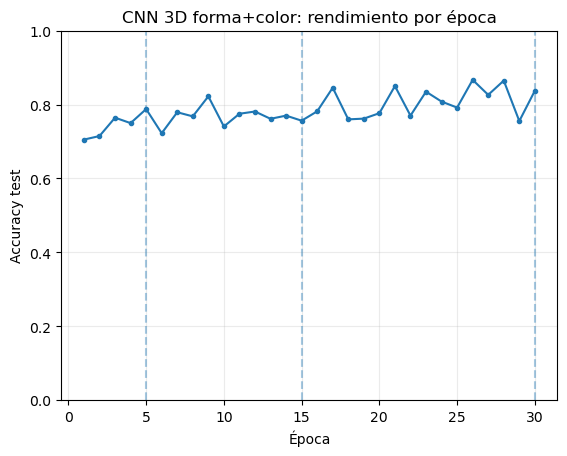

In [38]:
torch.manual_seed(1)
cnn_epocas, modelo_epocas = crear_clasificador_color()
pred_epocas, hist_epocas = entrenar(
    modelo_epocas, cnn_epocas,
    (Xtr, Ctr, ytr), (Xte, Cte, yte),
    epocas=30, devolver_historial=True,
    id_guardado='ejercicio_1_3d_color_30_epocas',
    firma_datos=(FIRMAS_DATOS[('entrenamiento', 1024)], FIRMAS_DATOS[('test', 1024)])
)
res_epocas = {ep: hist_epocas[ep-1] for ep in (5, 15, 30)}
print('Accuracy de test por época (corrida actual):')
for ep, accuracy in res_epocas.items():
    print(f'{ep:>2} épocas: {accuracy:.2%}')
guardar_json_seguro({'epocas': {str(k): v for k,v in res_epocas.items()},
                     'historial': hist_epocas},
                    CARPETA_RESULTADOS / 'ejercicio_1_epocas.json')
plt.plot(range(1, 31), hist_epocas, marker='.', label='Accuracy test')
for ep in (5, 15, 30):
    plt.axvline(ep, linestyle='--', alpha=0.4)
plt.xlabel('Época'); plt.ylabel('Accuracy test'); plt.ylim(0, 1)
plt.title('CNN 3D forma+color: rendimiento por época')
plt.grid(alpha=0.25)
plt.savefig(CARPETA_RESULTADOS / 'ejercicio_1_epocas.png', dpi=160, bbox_inches='tight')
plt.show()

**Respuesta.** La accuracy de test fue de **78,77 % a las 5 épocas**, **75,63 % a las 15** y **83,74 % a las 30**. Aunque el resultado final fue el mejor de esos tres, la evolución no fue constante: entre las épocas 5 y 15 hubo una caída de 3,14 puntos porcentuales, y después el rendimiento volvió a mejorar.

En el gráfico también se ven fluctuaciones entre épocas, incluso con valores intermedios superiores al de la época 30. Por eee motivo, no afirmaría que el modelo se estancó definitivamente, pero tampoco que seguir entrenando siempre lo vaya a mejorar. Para decidir el número de épocas más adecuado sería conveniente evaluar con un conjunto de validación separado del test. Estos resultados corresponden a tres momentos de una misma corrida de 30 épocas.


### Ejercicio 2
**En `a_nube` cambie `N=1024` por `N=256` y reentrene. ¿Qué pasa con la accuracy con menos puntos por objeto?**

Se generan nuevas nubes de 256 puntos sin modificar las de 1.024, y se entrena otra CNN 3D con forma y color durante 15 épocas.


In [39]:
torch.manual_seed(SEMILLA)
t0 = time.time()
# Reutiliza mapas de profundidad de N=1024 para evitar repetir miles de inferencias.
# Genera nubes N=256 independientes y las guarda para próximas sesiones.
Xtr256, Ctr256, _ = procesar_con_cache(
    arch_tr, 'entrenamiento', N=256, guardar_imagenes=False,
    tomar_profundidad_de='entrenamiento'
)
Xte256, Cte256, _ = procesar_con_cache(
    arch_te, 'test', N=256, guardar_imagenes=False,
    tomar_profundidad_de='test'
)
print('Nubes de 256 puntos:', tuple(Xtr256.shape), tuple(Xte256.shape),
      f'| tiempo: {time.time()-t0:.0f} s')

# CNN nueva, arquitectura y épocas idénticas; pesos separados de los otros ensayos.
torch.manual_seed(SEMILLA)
cnn_256, modelo_256 = crear_clasificador_color()
pred_256, hist_256 = entrenar(
    modelo_256, cnn_256,
    (Xtr256, Ctr256, ytr), (Xte256, Cte256, yte),
    epocas=15, devolver_historial=True,
    id_guardado='ejercicio_2_3d_color_256_puntos',
    firma_datos=(FIRMAS_DATOS[('entrenamiento', 256)], FIRMAS_DATOS[('test', 256)])
)
accuracy_256 = pred_256.eq(yte).float().mean().item()
print(f'1024 puntos: {accuracy_original:.2%}')
print(f' 256 puntos: {accuracy_256:.2%}')
print(f'Diferencia: {(accuracy_256-accuracy_original)*100:+.2f} puntos porcentuales')
guardar_json_seguro({'accuracy_1024': accuracy_original,
                     'accuracy_256': accuracy_256,
                     'historial_256': hist_256},
                    CARPETA_RESULTADOS / 'ejercicio_2_256_puntos.json')

[CACHÉ] entrenamiento, N=256: datos recuperados de entrenamiento_N256_ad66188e521ac598560c.pt
[CACHÉ] test, N=256: datos recuperados de test_N256_a16806ec04901c1146c7.pt
Nubes de 256 puntos: (4690, 256, 3) (1974, 256, 3) | tiempo: 0 s
[MODELO RECUPERADO] ejercicio_2_3d_color_256_puntos: 15 épocas; sin reentrenamiento.
1024 puntos: 73.35%
 256 puntos: 71.88%
Diferencia: -1.47 puntos porcentuales


**Respuesta.** Con **1.024 puntos** por objeto, la CNN 3D con forma y color obtuvo **73,35 %** de accuracy de test. Al reducir la nube a **256 puntos**, el resultado fue **71,88 %**, una disminución de **1,47 puntos porcentuales**.

La diferencia fue relativamente pequeña, aunque tiene sentido que una nube con menos puntos pueda perder detalles de la forma y del relieve al voxelizarse. En esta prueba, reducir cuatro veces la cantidad de puntos no provocó una caída grande en el rendimiento. Podría ser una alternativa para trabajar con una representación más liviana, pero no se midió el ahorro real de tiempo o memoria y harían falta más ejecuciones para confirmar la tendencia.


### Ejercicio 3
**Entrene la CNN 3D con forma y color pasando siempre `aum=False`, sin deformar puntos ni cambiar colores. Compare con el resultado original. ¿El aumento de datos ayuda a reconocer la variedad de test?**

Se entrena una nueva CNN durante 15 épocas sin aumento de datos y se compara con el modelo original, entrenado con aumento.


In [40]:
torch.manual_seed(SEMILLA)
cnn_sin_aug, modelo_sin_aug = crear_clasificador_color()
pred_sin_aug, hist_sin_aug = entrenar(
    modelo_sin_aug, cnn_sin_aug,
    (Xtr, Ctr, ytr), (Xte, Cte, yte),
    epocas=15, usar_aumento=False, devolver_historial=True,
    id_guardado='ejercicio_3_3d_color_sin_aumento',
    firma_datos=(FIRMAS_DATOS[('entrenamiento', 1024)], FIRMAS_DATOS[('test', 1024)])
)
accuracy_sin_aug = pred_sin_aug.eq(yte).float().mean().item()
print(f'Con data augmentation: {accuracy_original:.2%}')
print(f'Sin data augmentation: {accuracy_sin_aug:.2%}')
print(f'Diferencia (con - sin): {(accuracy_original-accuracy_sin_aug)*100:+.2f} pp')
guardar_json_seguro({'accuracy_con_aumento': accuracy_original,
                     'accuracy_sin_aumento': accuracy_sin_aug,
                     'historial_sin_aumento': hist_sin_aug},
                    CARPETA_RESULTADOS / 'ejercicio_3_aumento.json')

[MODELO RECUPERADO] ejercicio_3_3d_color_sin_aumento: 15 épocas; sin reentrenamiento.
Con data augmentation: 73.35%
Sin data augmentation: 71.38%
Diferencia (con - sin): +1.98 pp


**Respuesta.** El modelo entrenado **con aumento de datos** alcanzó **73,35 %** de accuracy de test, mientras que el modelo **sin aumento** obtuvo **71,38 %**. En esta ejecución, usar aumento mejoró el resultado en aproximadamente **1,98 puntos porcentuales**.

Las pequeñas modificaciones de escala y posición de los puntos, junto con los cambios de brillo y tono, pueden ayudar a que la red no dependa tanto del aspecto exacto de las frutas de entrenamiento. En este caso el aumento ayudó a reconocer mejor las variedades de test, aunque la mejora fue moderada. Como se hizo una sola corrida por configuración, no se puede asegurar que la diferencia sea igual al repetir el experimento.


## Resumen final de los experimentos

In [41]:
print('RESUMEN DE RESULTADOS — EJECUCIÓN ACTUAL (calculada o recuperada desde caché)')
print('-' * 62)
print(f'3D solo forma          : {pred_forma.eq(yte).float().mean().item():.2%}')
print(f'3D forma + color       : {accuracy_original:.2%}')
print(f'2D imagen              : {pred_2d.eq(yte).float().mean().item():.2%}')
print('-' * 62)
for ep in (5, 15, 30):
    print(f'3D color — {ep:2} épocas: {res_epocas[ep]:.2%}')
print(f'3D color — 256 puntos  : {accuracy_256:.2%}')
print(f'3D color — sin aumento : {accuracy_sin_aug:.2%}')
resumen_global = {
    'accuracy_modelos': {k: v['accuracy'] for k,v in resumen_modelos.items()},
    'ejercicio_1_epocas': {str(ep): res_epocas[ep] for ep in (5,15,30)},
    'ejercicio_2_256': accuracy_256,
    'ejercicio_3_sin_aumento': accuracy_sin_aug,
    'dataset': {'entrenamiento': len(arch_tr), 'test': len(arch_te)},
    'nota': 'Métricas de la ejecución actual: no mezclar con las históricas del Markdown.',
}
guardar_json_seguro(resumen_global, CARPETA_RESULTADOS / 'resumen_global.json')
print('Resumen actual guardado en:', (CARPETA_RESULTADOS / 'resumen_global.json').resolve())

RESUMEN DE RESULTADOS — EJECUCIÓN ACTUAL (calculada o recuperada desde caché)
--------------------------------------------------------------
3D solo forma          : 58.66%
3D forma + color       : 73.35%
2D imagen              : 88.91%
--------------------------------------------------------------
3D color —  5 épocas: 78.77%
3D color — 15 épocas: 75.63%
3D color — 30 épocas: 83.74%
3D color — 256 puntos  : 71.88%
3D color — sin aumento : 71.38%
Resumen actual guardado en: C:\Users\tolot\Documents\UBA\2026\5B\VPC3D\artefactos_frutas3d\resultados\resumen_global.json


### Conclusión general

En Fruits-360, la **CNN 2D** fue la que mejor clasificó las variedades no vistas, con **88,91 %** de accuracy. La CNN 3D mejoró claramente al agregar color (**73,35 %** frente a **58,66 %** usando solo forma), pero no alcanzó el rendimiento de la red que trabaja directamente sobre las imágenes RGB. En este problema, estimar profundidad y voxelizar no aportó una ventaja frente al enfoque 2D.

Los ejercicios mostraron que entrenar más épocas no produce una mejora continua, que usar menos puntos redujo ligeramente la accuracy y que el aumento de datos ayudó, aunque de manera moderada. En las cuatro fotografías externas hubo muchos más errores que en Fruits-360: eliminar el fondo mejoró las predicciones en varios casos, pero no alcanzó para resolverlas todas. Esto sugiere que los modelos aprendieron bien las condiciones bastante uniformes del dataset, pero tienen dificultades cuando cambian el fondo y la iluminación. Además, la profundidad generada a partir de una sola fotografía no equivale a una reconstrucción 3D completa.